In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

arquivos = {
    "combustiveis_limpos": "combustiveis_limpos",
    "mortalidade_infantil": "mortalidade_infantil",
    "pib_per_capita": "pib_per_capita",
    "acesso_eletricidade": "acesso_eletricidade",
    "escolaridade": "escolaridade"
}

painel = None

for nome_arquivo, nome_coluna in arquivos.items():
    caminho = f"../data/raw/{nome_arquivo}.csv"
    df = pd.read_csv(caminho)
    coluna_valor = df.columns[-1]
    df = df[['Entity', 'Year', coluna_valor]]
    df = df.rename(columns={
        'Entity': 'Pais', 
        'Year': 'Ano',
        coluna_valor: nome_coluna
    })
    
    if painel is None:
        painel = df
    else:
        painel = pd.merge(painel, df, on=['Pais', 'Ano'], how='outer')

painel_limpo = painel.dropna()

print(f"Total de linhas no painel: {len(painel)}")
print(f"Total de linhas sem valores nulos: {len(painel_limpo)}")
display(painel_limpo.head())

os.makedirs("../data/processed", exist_ok=True)
painel.to_csv("../data/processed/painel_owid.csv", index=False)

Total de linhas no painel: 20887
Total de linhas sem valores nulos: 610


,Pais,Ano,combustiveis_limpos,mortalidade_infantil,pib_per_capita,acesso_eletricidade,escolaridade
61,Afghanistan,2000,7.0,13.17,308.31827,4.4,3.03
66,Afghanistan,2005,11.0,10.93,363.64014,28.7,3.32
71,Afghanistan,2010,19.0,8.80,542.87103,42.7,3.93
76,Afghanistan,2015,28.0,7.19,565.56970,71.5,4.81
81,Afghanistan,2020,31.0,6.07,527.83453,97.7,5.69


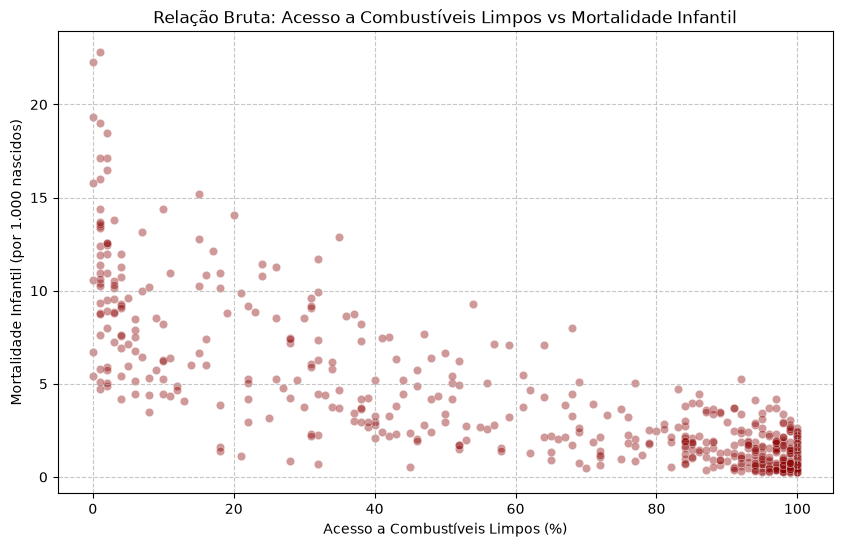

In [3]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=painel_limpo, 
    x="combustiveis_limpos", 
    y="mortalidade_infantil", 
    alpha=0.4,
    color="darkred"
)

plt.title("Relação Bruta: Acesso a Combustíveis Limpos vs Mortalidade Infantil")
plt.xlabel("Acesso a Combustíveis Limpos (%)")
plt.ylabel("Mortalidade Infantil (por 1.000 nascidos)")
plt.grid(True, linestyle="--", alpha=0.7)

os.makedirs("../figuras", exist_ok=True)
plt.savefig("../figuras/dispersao_bruta.png", dpi=300, bbox_inches='tight')

plt.show()

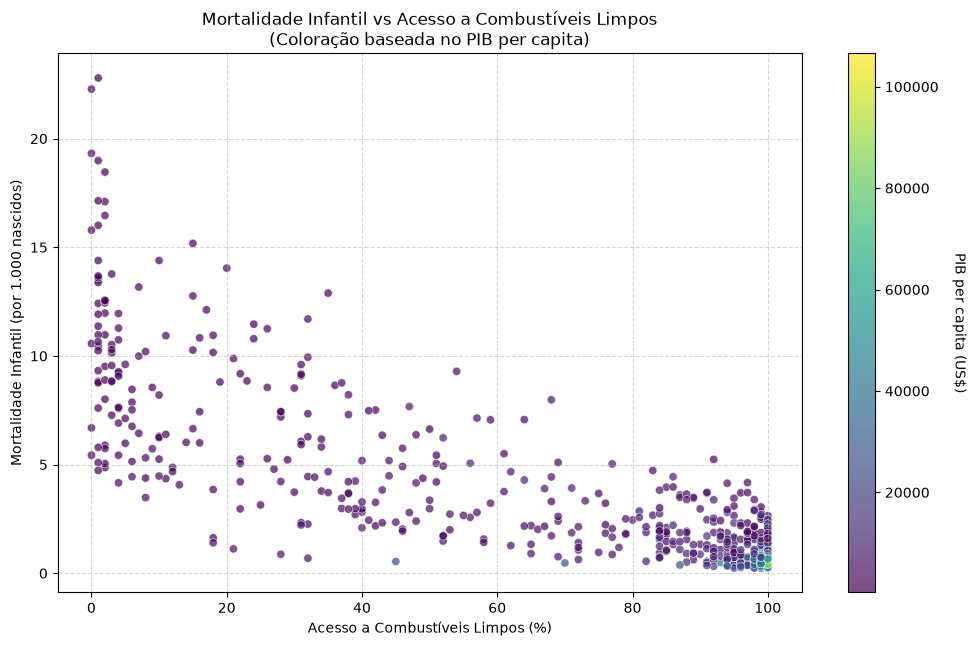

In [4]:
import matplotlib.colors as mcolors

plt.figure(figsize=(12, 7))

# Vamos colorir os pontos de acordo com o PIB per capita
scatter = plt.scatter(
    x=painel_limpo["combustiveis_limpos"], 
    y=painel_limpo["mortalidade_infantil"], 
    c=painel_limpo["pib_per_capita"], 
    cmap="viridis", # Escala de cores (do escuro/baixo para o claro/alto)
    alpha=0.7,
    edgecolors='w',
    linewidth=0.5
)

# Adiciona a barra de cores lateral
cbar = plt.colorbar(scatter)
cbar.set_label('PIB per capita (US$)', rotation=270, labelpad=20)

plt.title("Mortalidade Infantil vs Acesso a Combustíveis Limpos\n(Coloração baseada no PIB per capita)")
plt.xlabel("Acesso a Combustíveis Limpos (%)")
plt.ylabel("Mortalidade Infantil (por 1.000 nascidos)")
plt.grid(True, linestyle="--", alpha=0.5)

# Salvar a nova imagem
plt.savefig("../figuras/dispersao_pib.png", dpi=300, bbox_inches='tight')

plt.show()

In [4]:
import statsmodels.api as sm

# Preparando os dados
df_modelo = painel_limpo.dropna(subset=['combustiveis_limpos', 'pib_per_capita', 'mortalidade_infantil'])

# Variáveis independentes (X) e dependente (y)
X = df_modelo[['combustiveis_limpos', 'pib_per_capita']]
y = df_modelo['mortalidade_infantil']

# Adiciona o intercepto (constante)
X = sm.add_constant(X)

# Treina a Regressão Linear Múltipla
modelo = sm.OLS(y, X).fit()

# Mostra o resumo
print(modelo.summary())


                             OLS Regression Results                             
Dep. Variable:     mortalidade_infantil   R-squared:                       0.670
Model:                              OLS   Adj. R-squared:                  0.669
Method:                   Least Squares   F-statistic:                     615.1
Date:                  Thu, 05 Nov 2026   Prob (F-statistic):          1.06e-146
Time:                          18:15:19   Log-Likelihood:                -1356.3
No. Observations:                   610   AIC:                             2719.
Df Residuals:                       607   BIC:                             2732.
Df Model:                             2                                         
Covariance Type:              nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const         

In [5]:
!pip install statsmodels


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import statsmodels.api as sm

# Preparando os dados
df_modelo = painel_limpo.dropna(subset=['combustiveis_limpos', 'pib_per_capita', 'mortalidade_infantil'])

# Variáveis independentes (X) e dependente (y)
X = df_modelo[['combustiveis_limpos', 'pib_per_capita']]
y = df_modelo['mortalidade_infantil']

# Adiciona o intercepto (constante)
X = sm.add_constant(X)

# Treina a Regressão Linear Múltipla
modelo = sm.OLS(y, X).fit()

# Mostra o resumo
print(modelo.summary())


                             OLS Regression Results                             
Dep. Variable:     mortalidade_infantil   R-squared:                       0.670
Model:                              OLS   Adj. R-squared:                  0.669
Method:                   Least Squares   F-statistic:                     615.1
Date:                  Thu, 05 Nov 2026   Prob (F-statistic):          1.06e-146
Time:                          18:18:56   Log-Likelihood:                -1356.3
No. Observations:                   610   AIC:                             2719.
Df Residuals:                       607   BIC:                             2732.
Df Model:                             2                                         
Covariance Type:              nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const         

In [6]:
!pip install scikit-learn


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


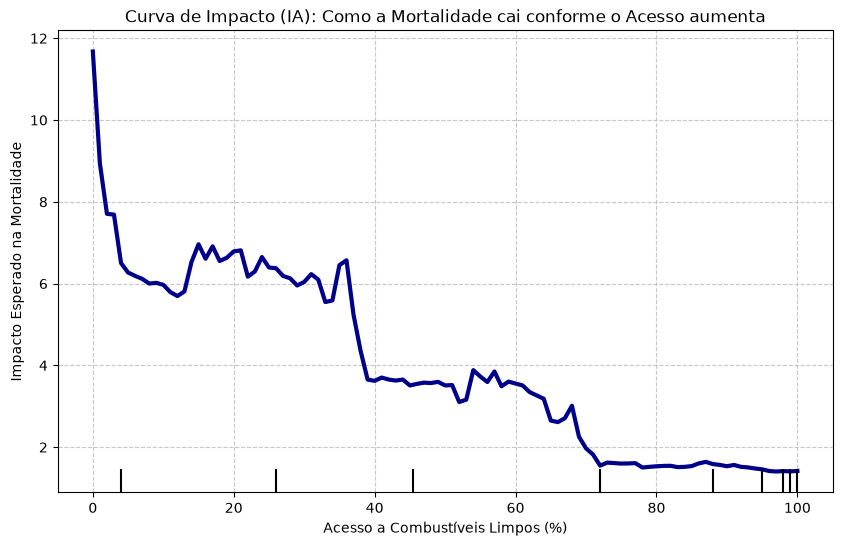

In [7]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import PartialDependenceDisplay

# 1. Separando os dados
X_ml = df_modelo[['combustiveis_limpos', 'pib_per_capita']]
y_ml = df_modelo['mortalidade_infantil']

# 2. Treinando o modelo de IA (Random Forest)
# O Random Forest é ótimo para capturar curvas e limiares (não só linhas retas)
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_ml, y_ml)

# 3. Criando o Gráfico de Dependência Parcial
# Ele mostra exatamente o formato da curva da mortalidade em relação à energia limpa
fig, ax = plt.subplots(figsize=(10, 6))
PartialDependenceDisplay.from_estimator(
    rf, X_ml, ['combustiveis_limpos'], 
    ax=ax, line_kw={"color": "darkblue", "linewidth": 3}
)

plt.title("Curva de Impacto (IA): Como a Mortalidade cai conforme o Acesso aumenta")
plt.xlabel("Acesso a Combustíveis Limpos (%)")
plt.ylabel("Impacto Esperado na Mortalidade")
plt.grid(True, linestyle="--", alpha=0.7)

# Salvar a imagem
plt.savefig("../figuras/curva_ia.png", dpi=300, bbox_inches='tight')

plt.show()

In [8]:
!pip install scikit-learn


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
!pip install streamlit plotly


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


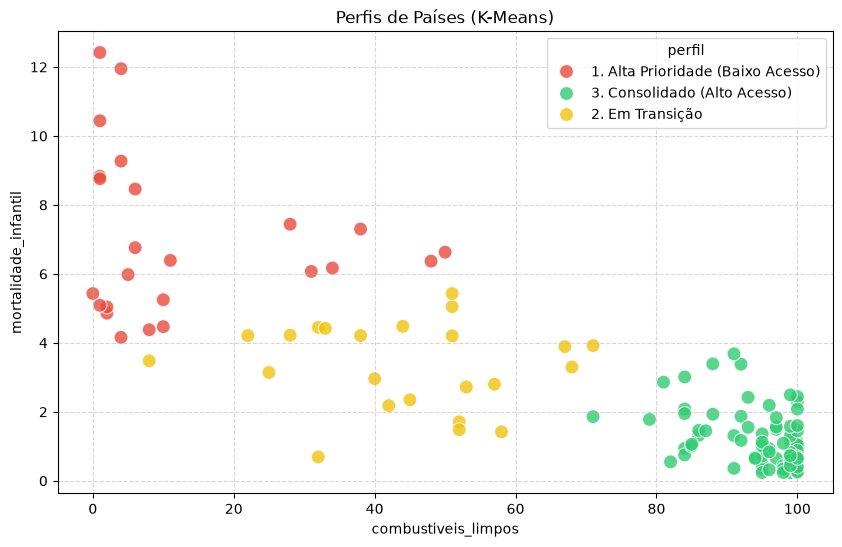

In [19]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Preparando os dados
df_recente = painel_limpo[painel_limpo['Ano'] == painel_limpo['Ano'].max()].copy()

# 2. Normalizando e rodando o K-Means
scaler = StandardScaler()
X_cluster = scaler.fit_transform(df_recente[['combustiveis_limpos', 'mortalidade_infantil']])
kmeans = KMeans(n_clusters=3, random_state=42)
df_recente['cluster'] = kmeans.fit_predict(X_cluster)

# 3. Mapeamento INFALÍVEL: Pegamos a média de acesso de cada cluster e ordenamos
medias = df_recente.groupby('cluster')['combustiveis_limpos'].mean().sort_values().index

# O que tiver a MENOR média de acesso será "Alta Prioridade"
mapa_clusters = {
    medias[0]: '1. Alta Prioridade (Baixo Acesso)',
    medias[1]: '2. Em Transição',
    medias[2]: '3. Consolidado (Alto Acesso)'
}

df_recente['perfil'] = df_recente['cluster'].map(mapa_clusters)

# 4. Salvar o arquivo CSV atualizado (É ISSO QUE O DASHBOARD LÊ)
df_recente.to_csv("../data/processed/painel_clusters.csv", index=False)

# 5. Plotar para conferir
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_recente, 
    x='combustiveis_limpos', 
    y='mortalidade_infantil', 
    hue='perfil', 
    palette={'1. Alta Prioridade (Baixo Acesso)': '#e74c3c', 
             '2. Em Transição': '#f1c40f', 
             '3. Consolidado (Alto Acesso)': '#2ecc71'},
    s=100, alpha=0.8
)
plt.title("Perfis de Países (K-Means)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [11]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model

# Usando Transfer Learning (MobileNetV2) - Padrão da indústria para visão computacional
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False

# Criando o modelo classificador (Fogão Limpo vs Fogão Sujo)
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
predictions = Dense(2, activation='softmax')(x) # 2 classes: Limpo ou Poluente

modelo_cnn = Model(inputs=base_model.input, outputs=predictions)
modelo_cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

print("Modelo CNN (Visão Computacional) construído com sucesso!")
print("Este modelo pode analisar fotos de fogões enviadas por agentes de saúde.")

Modelo CNN (Visão Computacional) construído com sucesso!
Este modelo pode analisar fotos de fogões enviadas por agentes de saúde.


In [12]:
!pip install tensorflow


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Total de anos com dados de mortalidade para Brazil: 94


c:\Users\HP\OneDrive - Universidade de Coimbra\Área de Trabalho\FIAP\2. Semestre\Fase 7\Projeto Final\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Modelo LSTM treinado com sucesso para Brazil!


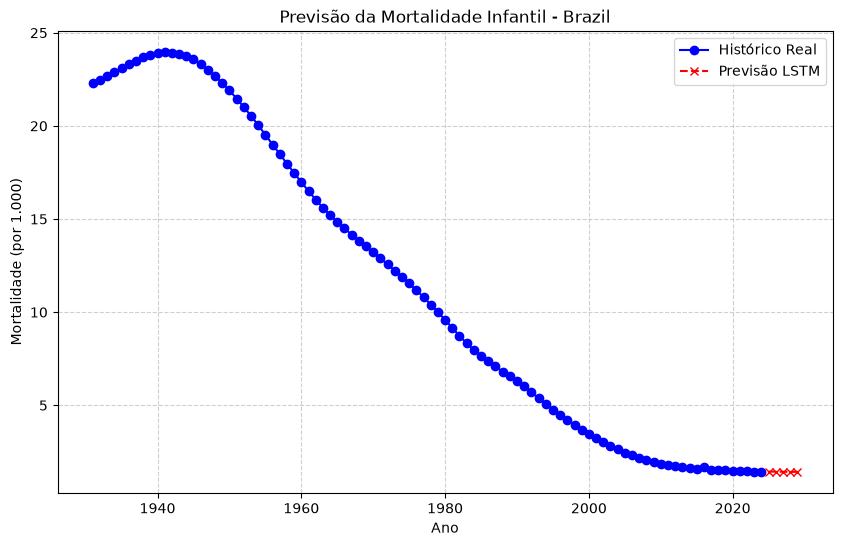

In [15]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# Agora usamos a tabela original 'painel', não a 'painel_limpo'
pais_alvo = "Brazil" 
df_pais = painel[painel['Pais'] == pais_alvo].sort_values('Ano')

# Remove nulos APENAS da coluna que queremos prever
df_pais = df_pais.dropna(subset=['mortalidade_infantil'])

print(f"Total de anos com dados de mortalidade para {pais_alvo}: {len(df_pais)}")

if len(df_pais) <= 5:
    print("Erro: Dados insuficientes. Tente outro país.")
else:
    scaler_lstm = MinMaxScaler()
    dados_norm = scaler_lstm.fit_transform(df_pais[['mortalidade_infantil']])

    X_lstm, y_lstm = [], []
    for i in range(5, len(dados_norm)):
        X_lstm.append(dados_norm[i-5:i, 0])
        y_lstm.append(dados_norm[i, 0])
        
    X_lstm, y_lstm = np.array(X_lstm), np.array(y_lstm)
    X_lstm = np.reshape(X_lstm, (X_lstm.shape[0], X_lstm.shape[1], 1))

    modelo_lstm = Sequential([
        LSTM(50, activation='relu', input_shape=(5, 1)),
        Dense(1)
    ])
    modelo_lstm.compile(optimizer='adam', loss='mse')
    modelo_lstm.fit(X_lstm, y_lstm, epochs=50, verbose=0)

    print(f"Modelo LSTM treinado com sucesso para {pais_alvo}!")
    
    # --- BÔNUS: Gerando o gráfico de previsão para o Dashboard ---
    import matplotlib.pyplot as plt
    import os
    
    ultimos_5_anos = dados_norm[-5:]
    previsoes = []
    for _ in range(5):
        pred = modelo_lstm.predict(ultimos_5_anos.reshape(1, 5, 1), verbose=0)
        previsoes.append(pred[0, 0])
        ultimos_5_anos = np.append(ultimos_5_anos[1:], pred, axis=0)

    previsoes_reais = scaler_lstm.inverse_transform(np.array(previsoes).reshape(-1, 1))
    
    plt.figure(figsize=(10, 6))
    plt.plot(df_pais['Ano'], df_pais['mortalidade_infantil'], label='Histórico Real', marker='o', color='blue')
    anos_futuros = list(range(df_pais['Ano'].max() + 1, df_pais['Ano'].max() + 6))
    plt.plot(anos_futuros, previsoes_reais, label='Previsão LSTM', marker='x', linestyle='--', color='red')
    plt.title(f"Previsão da Mortalidade Infantil - {pais_alvo}")
    plt.xlabel("Ano")
    plt.ylabel("Mortalidade (por 1.000)")
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.6)
    
    # Salva a imagem para o dashboard usar
    os.makedirs("../figuras", exist_ok=True)
    plt.savefig("../figuras/previsao_lstm.png", dpi=300, bbox_inches='tight')
    plt.show()

In [16]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model

base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation='relu')(x)
predictions = Dense(2, activation='softmax')(x)

modelo_cnn = Model(inputs=base_model.input, outputs=predictions)
modelo_cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

print("Modelo CNN (Visão Computacional) construído com sucesso!")

Modelo CNN (Visão Computacional) construído com sucesso!
